# Run analysis

Point `RUN_DIR` at any run folder. Everything is rebuilt from that folder: the model settings from `meta.json`, the depth rule from `config.yaml` and the dataset it names. Nothing is read from `configs/train.yaml`, so this works on runs whose config entry has since changed or that came from another machine.

1. **Logged curves:** the progress measures written during training.
2. **Recomputed from checkpoints:** the same measures computed again from each saved checkpoint. New measures can be added here without retraining; at matching steps they should equal the logged values.
3. **Final model:** key frequencies, every evaluation set, and accuracy by number of core passes (extended past the training range).
4. **Comparison:** key curves of several runs overlaid.

Figures are written to `<RUN_DIR>/analysis/` and `runs/comparisons/`.

In [ ]:
# setup: run from the repo root so paths resolve, and import the code in src/
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import torch as t
import yaml
from IPython.display import Image, display

import analysis
import plot_progress
import train

print("repo root:", ROOT)
print("torch", t.__version__, "| cuda:", t.cuda.is_available())

repo root: /home/saafetensors/Workspace/time-loops
torch 2.14.1+cu130 | cuda: True


## Parameters

`COMPARE` lists run folders to overlay; missing or unstarted runs are skipped, and runs still training show up to their latest evaluation. `SWEEP_T_MAX` is the deepest loop count tried on the final model. `PHASES` marks phase boundaries (steps) on the progress figures.

In [ ]:
RUN_DIR = "runs/ut_k1_T8_p113_h3_x6"
DATA_ROOT = "data/synthetic"
DEVICE = "cuda" if t.cuda.is_available() else "cpu"
SWEEP_T_MAX = 32
PHASES = []

COMPARE_NAME = "anchors_vs_ut"
COMPARE = [
    "runs/anchor_p113_h1",
    "runs/anchor_p113_h3_x6",
    "runs/anchor_nope_p113_h3_x6",
    "runs/ut_k1_T8_p113_h3_x6",
    "runs/ut_statenorm_k1_T8_p113_h3_x6",
]

In [ ]:
run = analysis.load_run(RUN_DIR, DATA_ROOT, DEVICE)
out_dir = run["run_dir"] / "analysis"
out_dir.mkdir(exist_ok=True)
meta = run["meta"]

print(yaml.safe_dump(run["entry"], sort_keys=False))
print("model:", run["cfg"])
print(f"eval depth T = {run['T']} | trained {meta['steps']} steps on {meta['device']} | "
      f"git {meta['git']['commit'][:7]}{' (dirty)' if meta['git']['dirty'] else ''}")
ckpts = analysis.checkpoints(run)
print(f"{len(ckpts)} checkpoints: steps {[s for s, _ in ckpts]}")
if run["data_changed"]:
    print("WARNING: dataset files changed since this run trained:", run["data_changed"])
else:
    print(f"dataset {meta['data']['name']} matches what the run trained on")

name: ut_k1_T8_p113_h3_x6
data: p113_h3_x6
seed: 0
model:
  pos: none
  norm: none
  n_prelude: 0
  k: 1
  core_shared: true
  injection: none
  state_init: embed
  n_coda: 0
depth:
  rule: fixed
  T: 8
train:
  steps: 40000
  eval_every: 100
  sweep_every: 1000
  eval_T_max: 32

model: ModelConfig(p=113, pos='none', n_ctx=0, norm='none', n_prelude=0, k=1, core_shared=True, n_core_copies=1, injection='none', state_init='embed', n_coda=0, state_norm=False, d_model=128, num_heads=4, d_head=32, d_mlp=512)
eval depth T = 8 | trained 40000 steps on NVIDIA GeForce RTX 4090 | git 380ac71 (dirty)
25 checkpoints: steps [100, 128, 165, 211, 271, 348, 447, 574, 737, 946, 1214, 1558, 2000, 2567, 3295, 4229, 5429, 6968, 8944, 11481, 14736, 18915, 24278, 31163, 40000]
dataset p113_h3_x6 matches what the run trained on


## Logged curves

Nanda et al.'s progress measures on the hop-1 table (train/test/restricted/excluded loss, Fourier sparsity, weight norm), plus validation accuracy for each hop, as logged every `eval_every` steps during training.

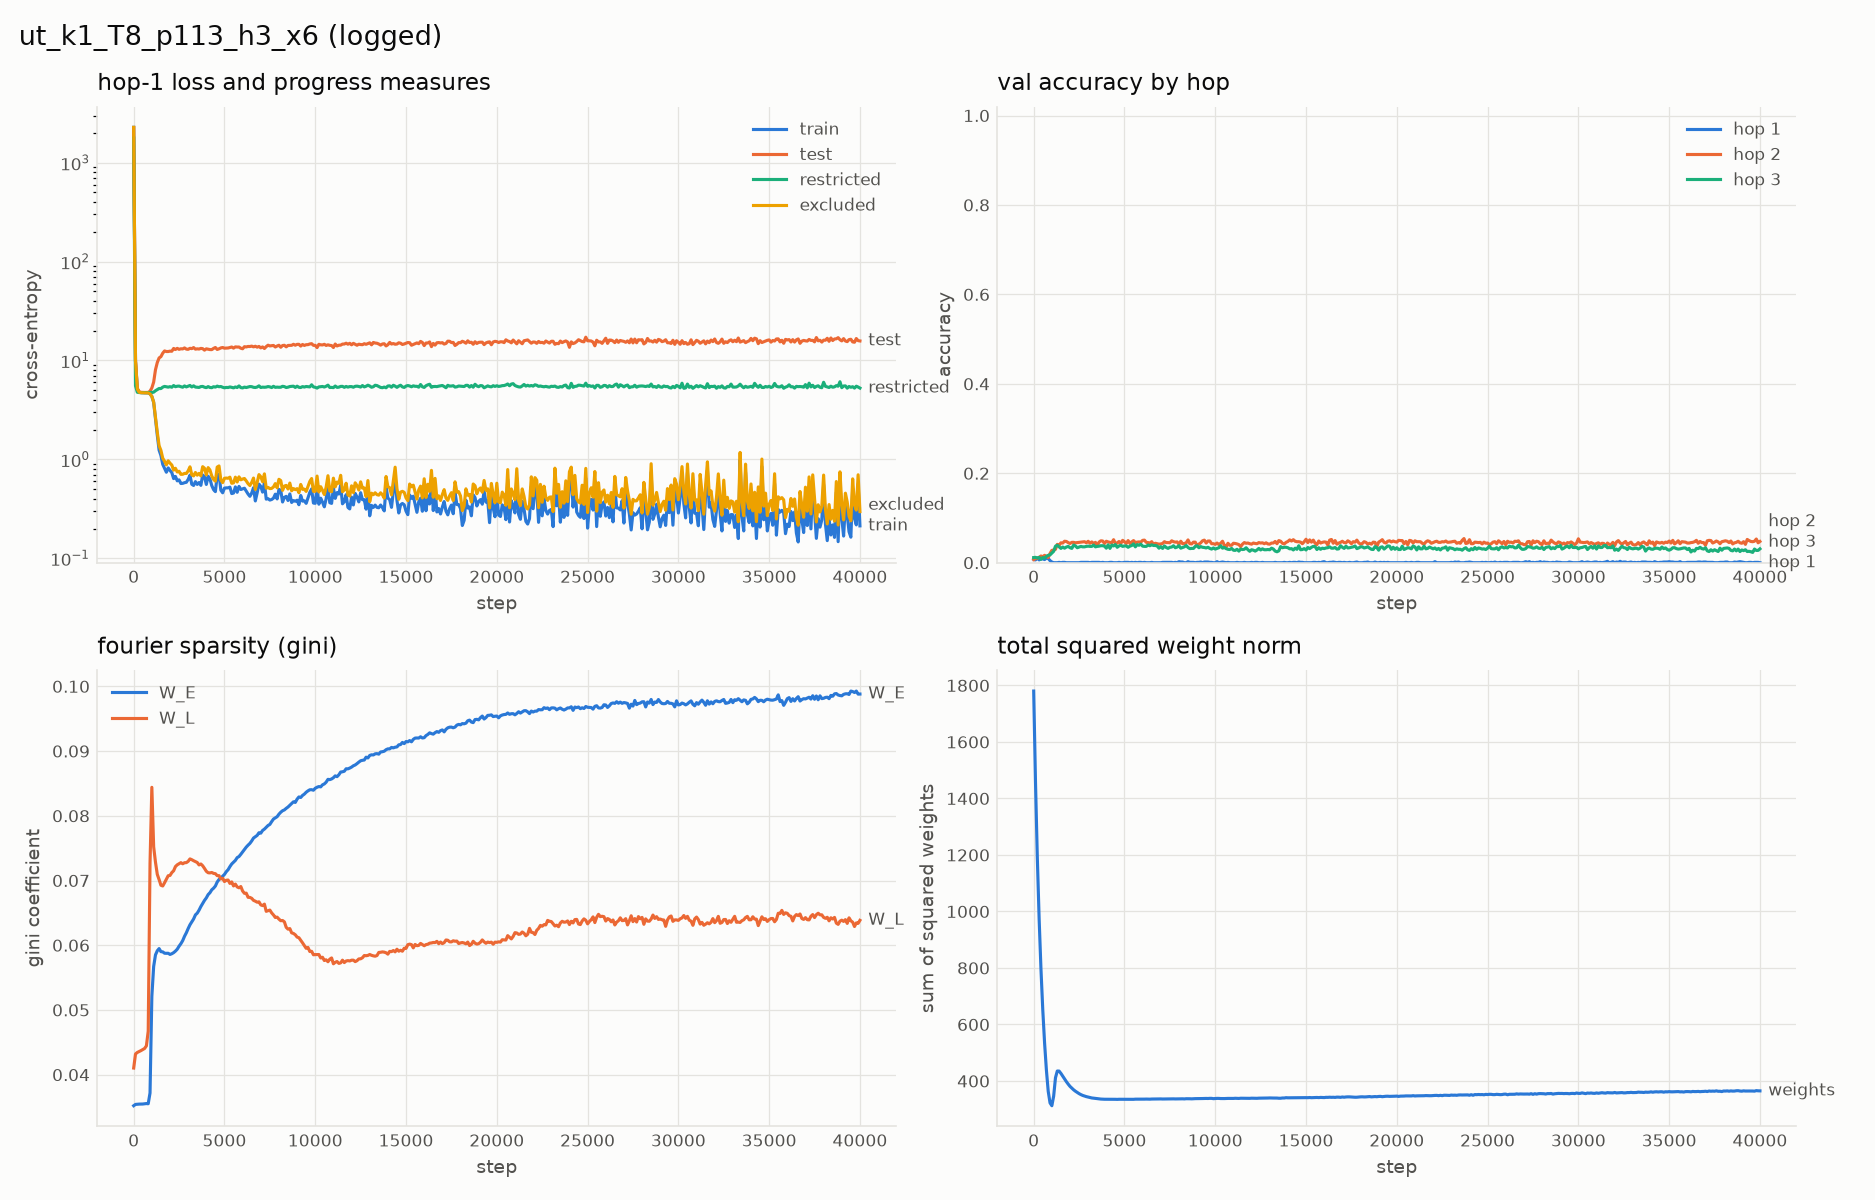

In [ ]:
display(Image(filename=str(plot_progress.plot_rows(
    plot_progress.load_evals(run["run_dir"]), f"{run['name']} (logged)", out_dir / "progress_logged.png", PHASES))))

## Recomputed from checkpoints

The same measures, recomputed from each saved checkpoint (checkpoints are log-spaced, so early training is denser). The check below compares them with the logged values at the same steps.

In [ ]:
rows = analysis.recompute(run, DEVICE, log=print)
logged = {r["step"]: r for r in plot_progress.load_evals(run["run_dir"])}
diffs = [abs(r["progress"]["restricted_loss"] - logged[r["step"]]["progress"]["restricted_loss"])
         for r in rows if r["step"] in logged]
print(f"\nlargest restricted-loss difference from the logged values over {len(diffs)} steps: {max(diffs):.2e}")

step    100  val acc h1=0.006 h2=0.009 h3=0.012  restricted 5.545


step    128  val acc h1=0.008 h2=0.014 h3=0.015  restricted 5.069


step    165  val acc h1=0.009 h2=0.012 h3=0.013  restricted 4.844


step    211  val acc h1=0.010 h2=0.009 h3=0.009  restricted 4.764


step    271  val acc h1=0.007 h2=0.011 h3=0.012  restricted 4.741


...

step  14736  val acc h1=0.002 h2=0.049 h3=0.033  restricted 5.335


step  18915  val acc h1=0.000 h2=0.051 h3=0.030  restricted 5.614


step  24278  val acc h1=0.001 h2=0.044 h3=0.032  restricted 5.322


step  31163  val acc h1=0.000 h2=0.051 h3=0.029  restricted 5.398


step  40000  val acc h1=0.000 h2=0.048 h3=0.031  restricted 5.262

largest restricted-loss difference from the logged values over 3 steps: 0.00e+00


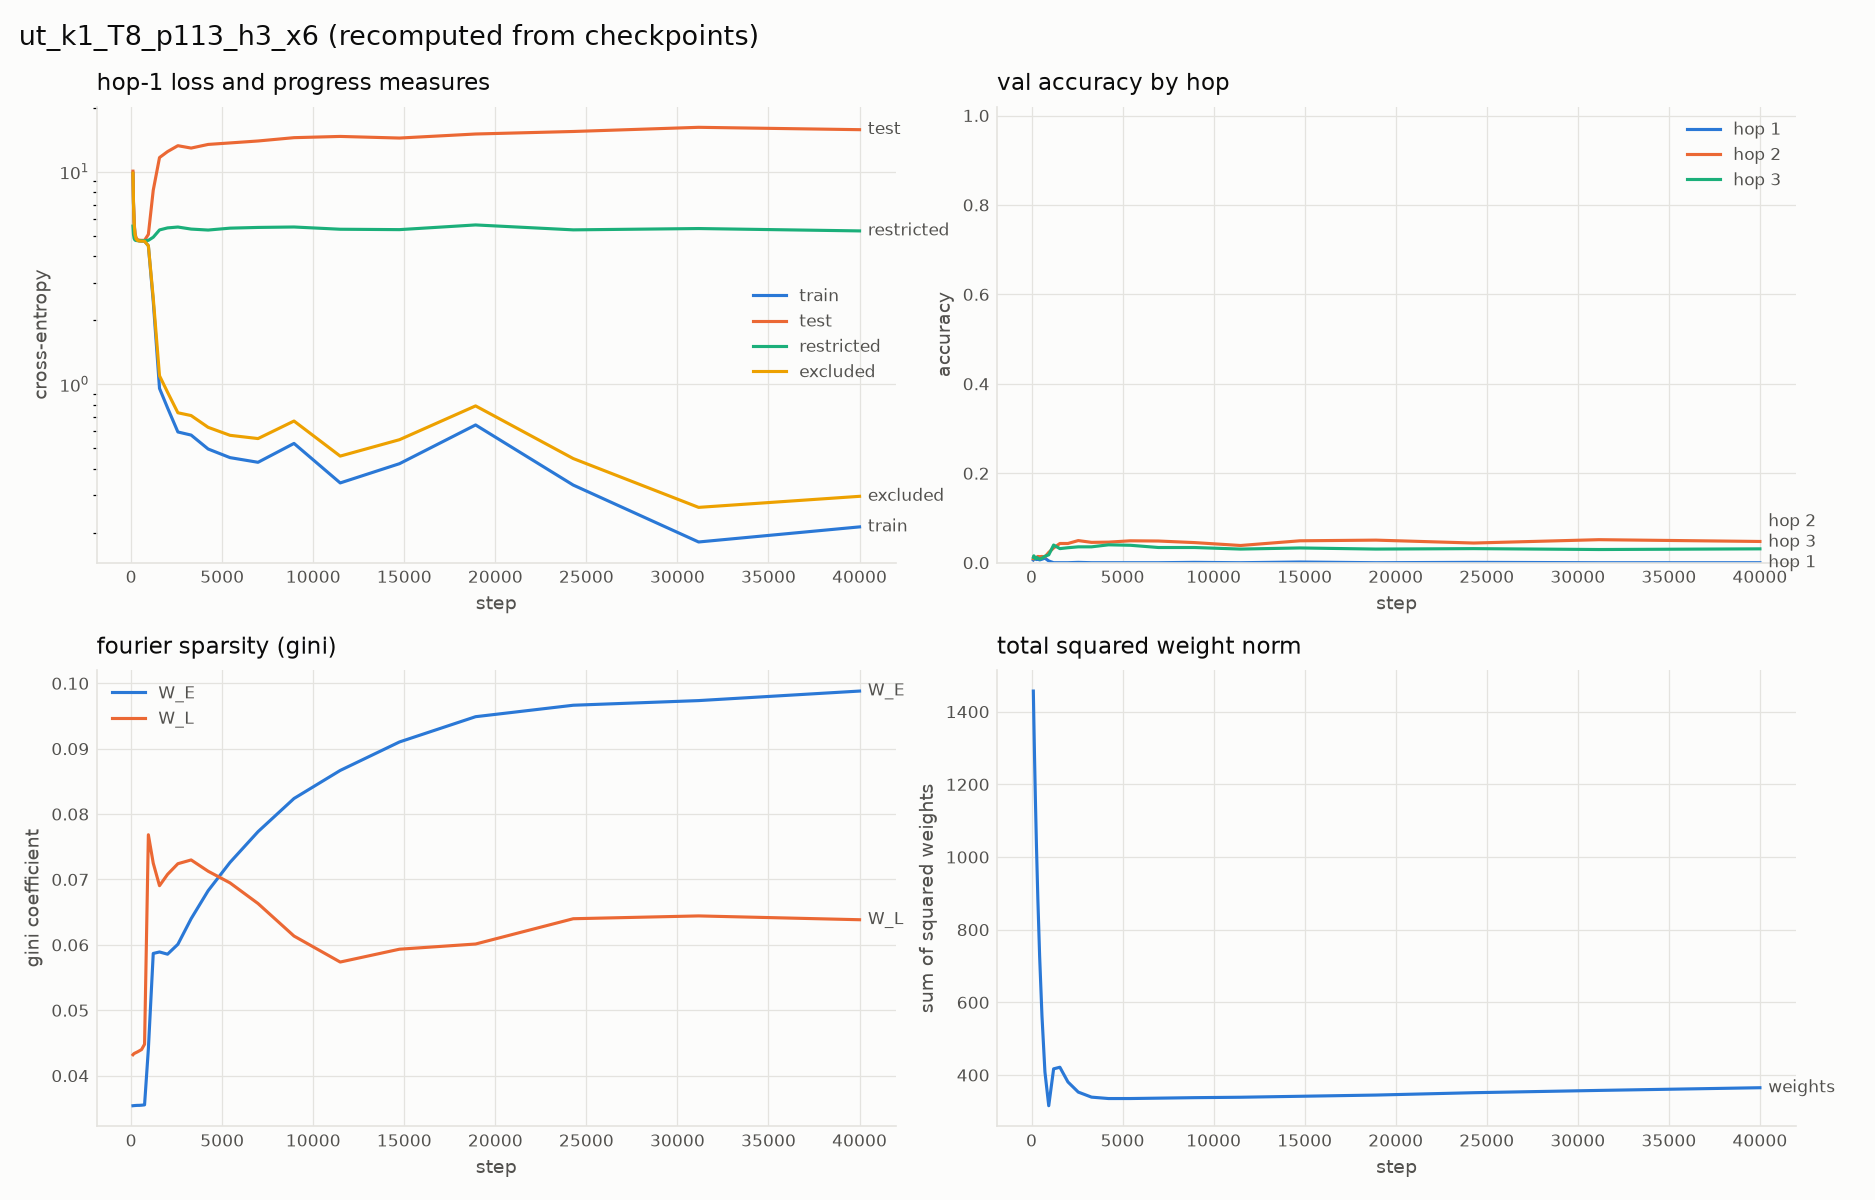

In [ ]:
display(Image(filename=str(plot_progress.plot_rows(
    rows, f"{run['name']} (recomputed from checkpoints)", out_dir / "progress_recomputed.png", PHASES))))

## Final model

Key frequencies are the five frequencies with the largest cos/sin(w(a+b)) component in the hop-1 logits; the excluded loss for each one shows how much the model relies on it.

In [ ]:
final_step, final_path = ckpts[-1]
last = rows[-1]["progress"]
print(f"step {final_step}: key frequencies {last['key_freqs']}")
print("excluded loss per key frequency:", [round(v, 3) for v in last["excluded_loss_per_freq"]])
print(f"restricted {last['restricted_loss']:.3f} | excluded {last['excluded_loss']:.3f} | "
      f"grid test acc {last['grid_test_acc']:.3f} | gini W_E {last['gini_W_E']:.3f}\n")

model = analysis.load_model(run, final_path, DEVICE)
for name, groups in run["data"]["sets"].items():
    res = train.evaluate(model, groups, run["T"], run["chunk_size"], analysis.eval_generator(run, DEVICE))
    print(f"{name:<18}", "  ".join(f"{label}: {v['acc']:.3f}" for label, v in res.items()))

step 40000: key frequencies [50, 37, 45, 47, 38]
excluded loss per key frequency: [0.235, 0.229, 0.225, 0.225, 0.224]
restricted 5.262 | excluded 0.296 | grid test acc 0.001 | gini W_E 0.099



train              1: 0.990  2: 0.664  3: 0.705
val                1: 0.000  2: 0.048  3: 0.031
extrap_depth       4: 0.029  5: 0.024  6: 0.025
systematic         2.k1: 0.015  2.k2: 0.005  3.k1: 0.040  3.k2: 0.027  3.k3: 0.005


systematic_extrap  4.k1: 0.022  4.k2: 0.024  4.k3: 0.036  4.k4: 0.000  5.k1: 0.015  5.k2: 0.028  5.k3: 0.020  5.k4: 0.025  5.k5: 0.003  6.k1: 0.033  6.k2: 0.024  6.k3: 0.006  6.k4: 0.030  6.k5: 0.027  6.k6: 0.021


Accuracy as a function of the number of core passes for the final model, up to `SWEEP_T_MAX`. Hops beyond the training range are depth extrapolation; the dashed line is the training depth. Only models with a shared core can be run past their training depth.

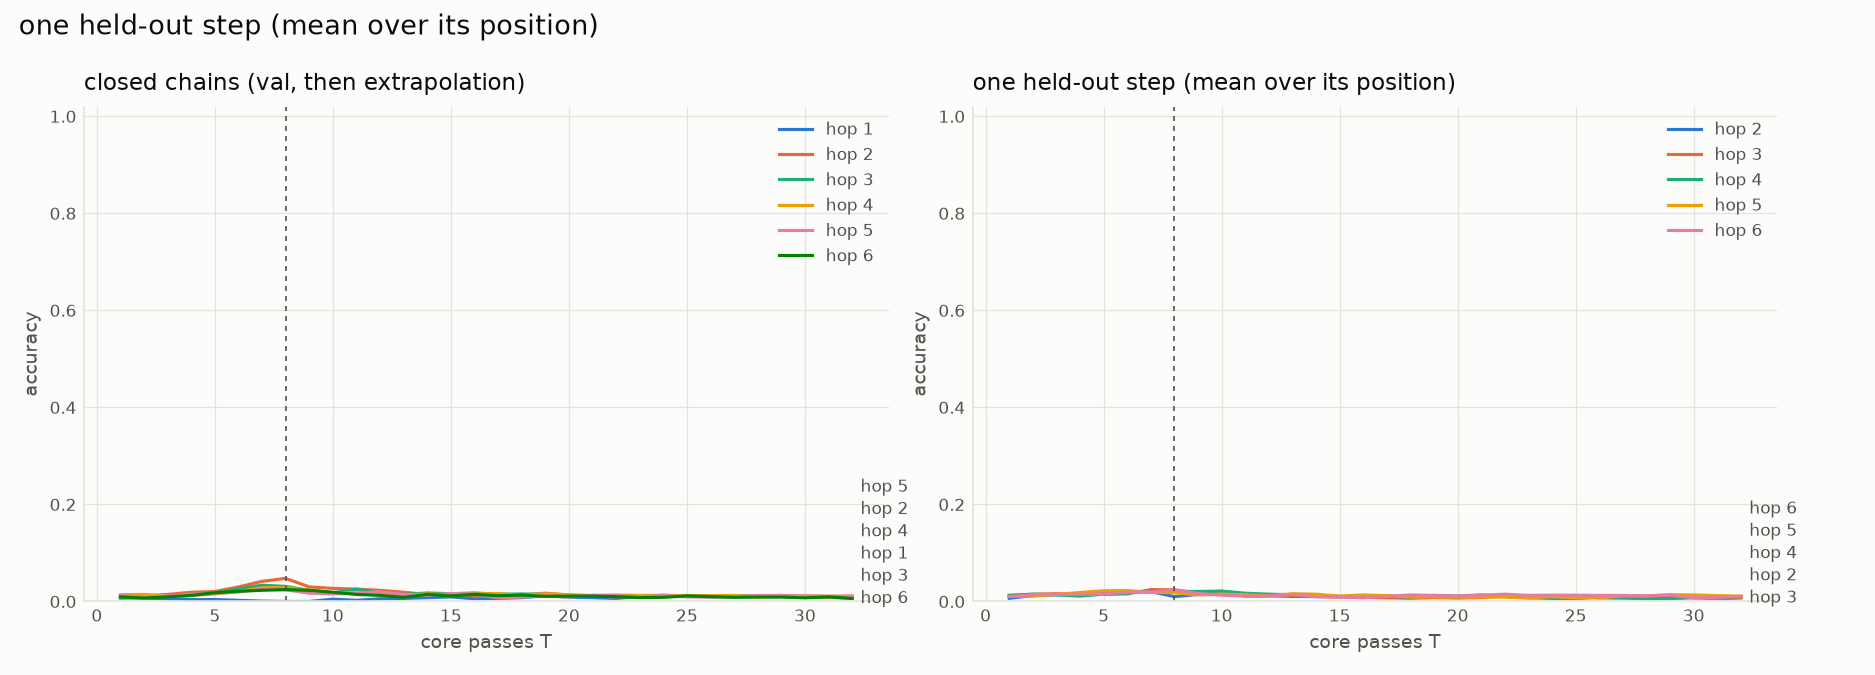

In [ ]:
if run["cfg"].core_shared:
    by_T = analysis.depth_sweep(run, final_path, SWEEP_T_MAX, DEVICE)
    title = f"{run['name']}: accuracy by depth at step {final_step}"
    display(Image(filename=str(plot_progress.plot_sweep(by_T, title, out_dir / "depth_sweep.png", train_T=run["T"]))))
else:
    print("unshared core: no depth sweep")

## Comparison

Logged curves of every run in `COMPARE`, one colour per run in list order. The last panel uses each run's deepest trained hop (hop 1 for hop-1-only runs).

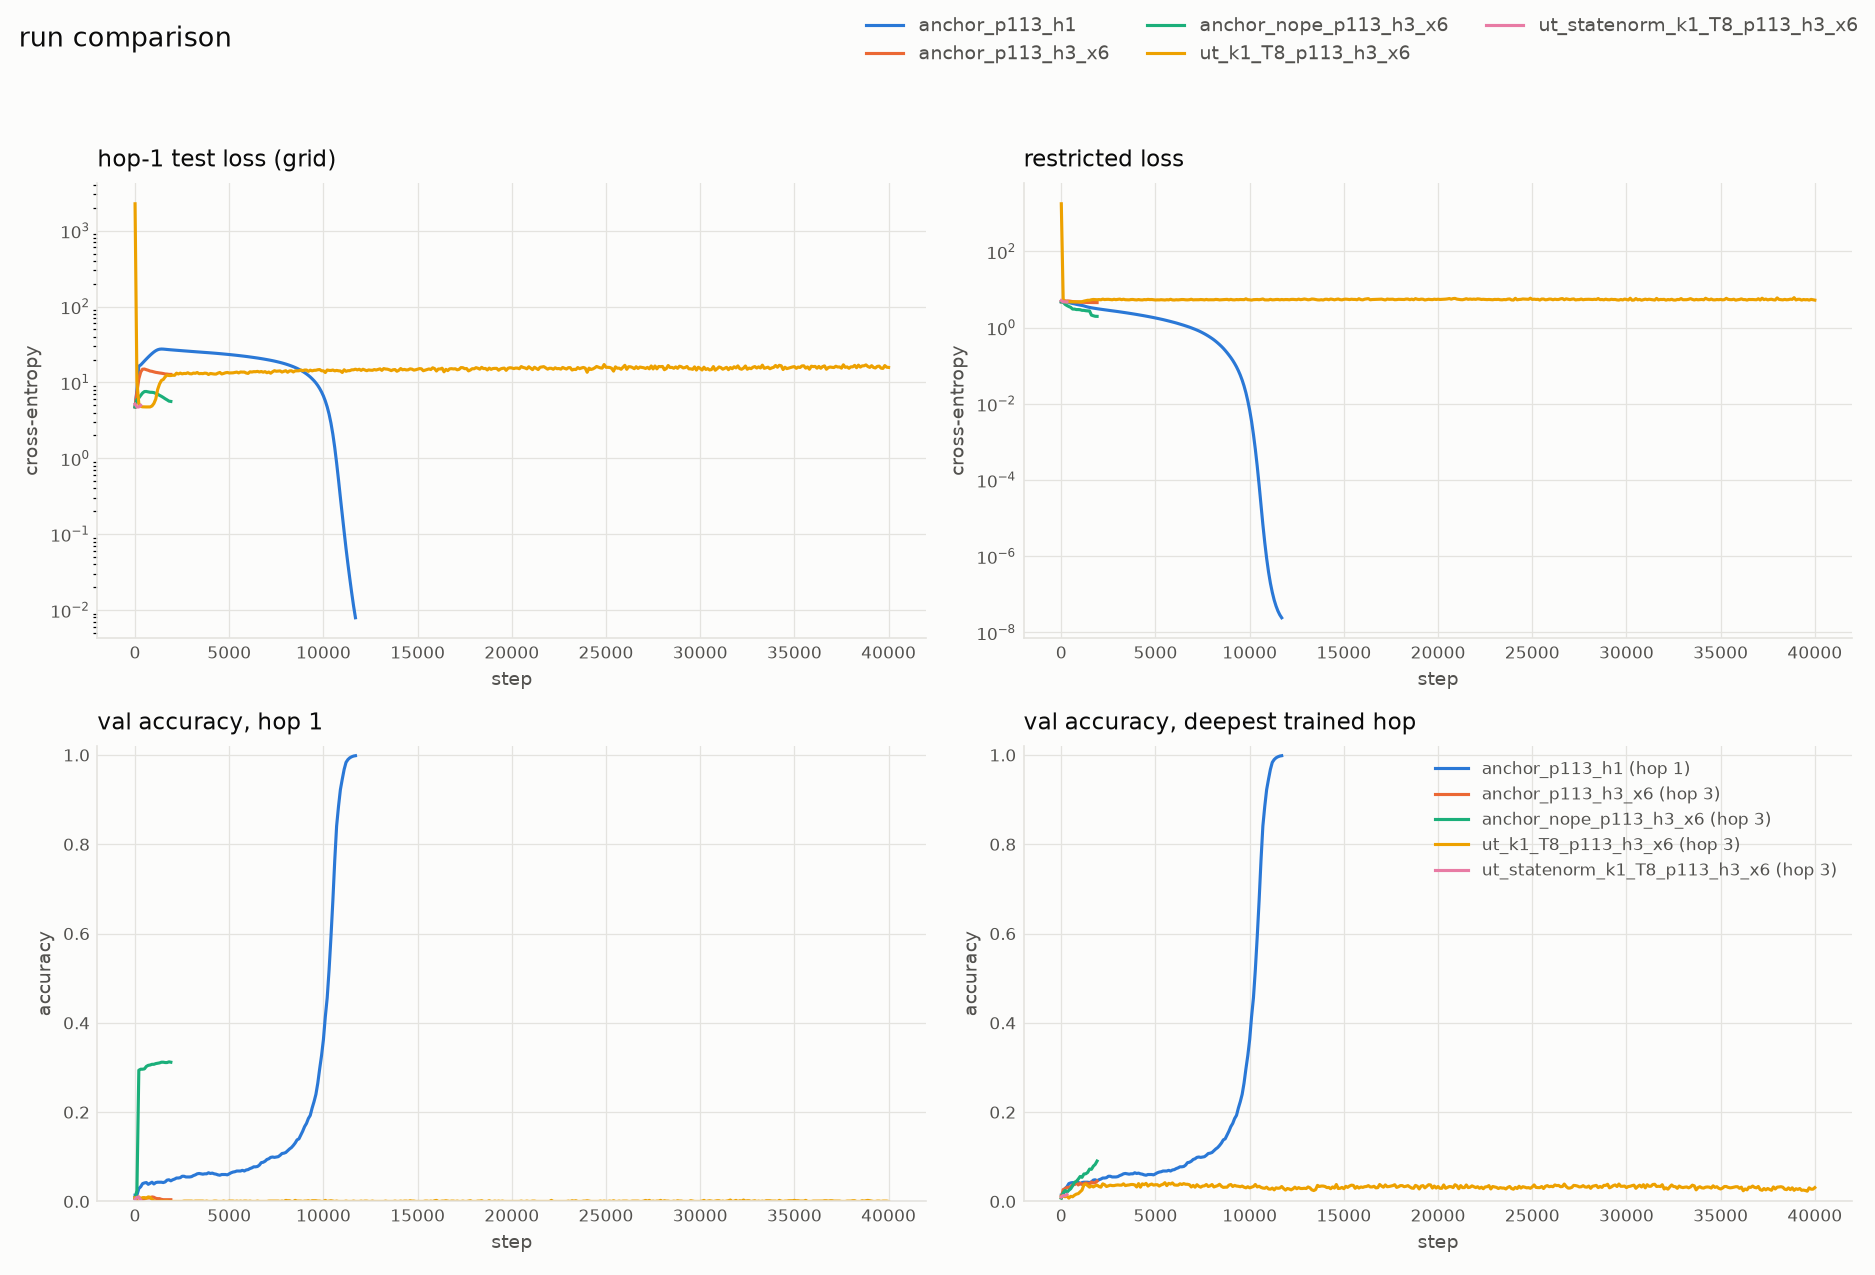

anchor_p113_h1                     step  11700   hop 1: 0.998
anchor_p113_h3_x6                  step   1900   hop 1: 0.004  hop 2: 0.040  hop 3: 0.045
anchor_nope_p113_h3_x6             step   1900   hop 1: 0.312  hop 2: 0.203  hop 3: 0.090
ut_k1_T8_p113_h3_x6                step  40000   hop 1: 0.000  hop 2: 0.048  hop 3: 0.031
ut_statenorm_k1_T8_p113_h3_x6      step    300   hop 1: 0.003  hop 2: 0.018  hop 3: 0.015


In [ ]:
runs = []
for d in map(Path, COMPARE):
    if (d / "metrics.jsonl").exists():
        runs.append((d.name, plot_progress.load_evals(d)))
    else:
        print("skipping (no metrics yet):", d)
out = plot_progress.plot_compare(runs, Path("runs/comparisons") / f"{COMPARE_NAME}.png")
display(Image(filename=str(out)))

# latest logged val accuracy per run
for name, evals in runs:
    r = evals[-1]
    print(f"{name:<34} step {r['step']:>6}  ", "  ".join(f"hop {h}: {v['acc']:.3f}" for h, v in r["val"].items()))